# 02. RNN 입력·출력 shape와 분류 logits 확인
기본필수 `02_rnn.py`를 바탕으로 **입력 `(B,6,3)` → RNN → 마지막 은닉 상태 `(B,8)` → 분류 logits `(B,2)`** 흐름을 확인합니다. 원본 코드에서 B=4이며, 모든 자료의 길이는 6입니다.

## 0. 작업 전 준비사항
PyTorch, pandas, matplotlib이 설치된 Python 커널에서 **Run All**로 실행합니다. CPU 난수 텐서를 사용하며 데이터 다운로드는 필요하지 않습니다. 원본 Python 파일은 수정하지 않습니다. 표와 그림은 `20261103/01_기본필수/docs/outputs`에 저장합니다.

이 예제는 학습 전 순전파와 shape를 확인하는 실습입니다. 실제 정답 라벨과 학습 과정이 없으므로 출력으로 모델의 정확도를 판단하지 않습니다.

In [1]:
%matplotlib inline
from pathlib import Path
import runpy
import torch
from torch import nn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
day_root = next((candidate for parent in (cwd, *cwd.parents)
                 for candidate in (parent / "20261103", parent)
                 if (candidate / "01_기본필수" / "02_rnn.py").is_file()), None)
if day_root is None:
    raise FileNotFoundError("이 저장소 안에서 실행하세요.")
out = day_root / "01_기본필수" / "docs" / "outputs"
out.mkdir(parents=True, exist_ok=True)
# 실제 파일을 실행해 입력·모델·출력·분류층을 읽습니다.
state = runpy.run_path(str(day_root / "01_기본필수" / "02_rnn.py"))
x, rnn, output, h_n, head, logits = (state[name] for name in ["x", "rnn", "output", "h_n", "head", "logits"])
B, T, F = x.shape
print("B, T, F:", B, T, F)

입력: (4, 6, 3)
output / h_n: (4, 6, 8) (1, 4, 8)
logits: (4, 2)
마지막 시점 일치: True
B, T, F: 4 6 3


## 1. `(B,6,3)` 입력을 RNN에 전달하기
```python
x = torch.randn(4, 6, 3)
rnn = nn.RNN(input_size=3, hidden_size=8, batch_first=True)
output, h_n = rnn(x)
```

| 기호 | 의미 | 이번 값 |
| --- | --- | --- |
| B | 독립된 시퀀스의 수 | 4 |
| T | 시퀀스 하나의 시점 수 | 6 |
| F | 한 시점의 입력 특성 수 | 3 |
| H | RNN이 만드는 은닉 특성 수 | 8 |

`x[b,t,:]`는 b번째 자료의 t번째 시점에 있는 특성 3개입니다. 자료 4개가 각각 6시점을 가지며, 시점의 순서를 유지해 RNN으로 처리합니다. `torch.randn()`은 정규분포 난수이며 실제 데이터셋은 아닙니다.

`input_size=3`은 입력의 마지막 축과 같아야 합니다. `hidden_size=8`은 각 시점의 정보를 표현할 은닉 벡터 크기입니다. `batch_first=True`는 입력과 output의 축을 B·T·특성 순으로 해석하도록 합니다. 초기 은닉 상태를 생략했으므로 0으로 시작합니다. 기본 설정은 1층·단방향·tanh입니다.

RNN은 각 시점의 입력과 이전 은닉 상태를 함께 사용해 다음 은닉 상태를 만듭니다. 따라서 마지막 은닉 상태에는 앞 시점의 정보가 계산을 통해 반영되지만 모든 과거 정보가 완벽히 보존된다는 뜻은 아닙니다.

In [2]:
print("첫 번째 자료의 입력 (6시점 × 3특성):\n", x[0])
assert x.shape == (B, 6, 3)
# 실제 파일에서 생성한 RNN에 같은 입력을 다시 전달해 확인합니다.
with torch.no_grad():
    checked_output, checked_h_n = rnn(x)
assert torch.allclose(checked_output, output)
assert torch.allclose(checked_h_n, h_n)
print("output:", tuple(checked_output.shape))
print("h_n:", tuple(checked_h_n.shape))

첫 번째 자료의 입력 (6시점 × 3특성):
 tensor([[ 1.9269,  1.4873,  0.9007],
        [-2.1055,  0.6784, -1.2345],
        [-0.0431, -1.6047, -0.7521],
        [ 1.6487, -0.3925, -1.4036],
        [-0.7279, -0.5594, -0.7688],
        [ 0.7624,  1.6423, -0.1596]])
output: (4, 6, 8)
h_n: (1, 4, 8)


## 2. output과 h_n의 차이
| 텐서 | 일반 shape | 이번 shape | 담고 있는 내용 |
| --- | --- | --- | --- |
| `output` | `(B,T,H)` | `(4,6,8)` | 마지막 RNN 층의 모든 시점 은닉 출력 |
| `h_n` | `(층 수 × 방향 수,B,H)` | `(1,4,8)` | 각 층·방향의 최종 은닉 상태 |
| `output[:,-1,:]` | `(B,H)` | `(4,8)` | 모든 자료에서 마지막 시점 선택 |
| `h_n[-1]` | `(B,H)` | `(4,8)` | 이번 단방향 모델의 마지막 층 최종 상태 |

**batch_first=True여도 h_n은 B가 첫 축이 아닙니다.** `h_n[-1]`의 -1은 마지막 배치나 마지막 시점을 직접 고르는 인덱스가 아니라 첫 축의 마지막 층·방향 상태를 선택합니다. 이번에는 1층·단방향이므로 그 축의 크기는 1입니다.

이번 고정 길이·단방향 설정에서는 `output[:,-1,:]`와 `h_n[-1]`이 같습니다. 마지막 입력 `x[:,-1,:]`와 같다는 의미는 아닙니다. 가변 길이 자료에 Padding을 붙이거나 양방향 RNN을 쓰는 경우에는 마지막 실제 시점·방향을 별도로 고려해야 합니다.

마지막 시점 output shape: (4, 8)
마지막 층 h_n shape: (4, 8)
두 텐서 일치: True
최대 절대 차이: 0.0


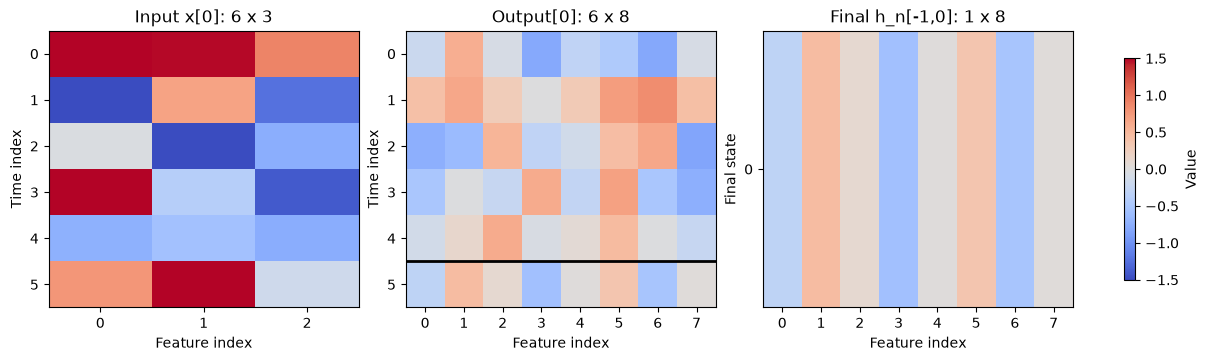

In [3]:
last_output = output[:, -1, :]
last_hidden = h_n[-1]
assert output.shape == (B, 6, 8)
assert h_n.shape == (1, B, 8)
assert torch.allclose(last_output, last_hidden)
print("마지막 시점 output shape:", tuple(last_output.shape))
print("마지막 층 h_n shape:", tuple(last_hidden.shape))
print("두 텐서 일치:", torch.allclose(last_output, last_hidden))
print("최대 절대 차이:", (last_output-last_hidden).abs().max().item())

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), constrained_layout=True)
arrays = [x[0].detach().numpy(), output[0].detach().numpy(), h_n[-1,0].detach().numpy()[None,:]]
titles = ["Input x[0]: 6 x 3", "Output[0]: 6 x 8", "Final h_n[-1,0]: 1 x 8"]
for ax, values, title in zip(axes, arrays, titles):
    im = ax.imshow(values, cmap="coolwarm", aspect="auto", vmin=-1.5, vmax=1.5)
    ax.set_title(title)
    ax.set_xlabel("Feature index")
    ax.set_xticks(range(values.shape[1]))
    ax.set_yticks(range(values.shape[0]))
    ax.set_ylabel("Time index" if values.shape[0] == 6 else "Final state")
    if title.startswith("Output"):
        ax.axhline(4.5, color="black", linewidth=2)
fig.colorbar(im, ax=axes, label="Value", shrink=0.8)
fig.savefig(out / "rnn_input_output_hidden.png", dpi=140)
plt.show()
plt.close(fig)

## 3. 은닉 특성 8개를 두 클래스 점수로 바꾸기
TODO B02는 다음처럼 구현합니다.

```python
head = nn.Linear(in_features=8, out_features=2, bias=True)
logits = head(h_n[-1])
```

Linear는 마지막 축의 크기를 8에서 2로 변환하므로 `(B,8) → (B,2)`가 됩니다. 4개 자료 각각에 클래스 0·1의 점수 한 쌍이 나옵니다. 클래스 이름은 이 난수 예제에서 별도로 정의하지 않았습니다.

층을 만드는 `nn.Linear(...)`와 텐서를 계산하는 `head(...)`는 역할이 다릅니다. bias=True는 편향을 포함하는 기본 설정입니다. 학습 파라미터는 가중치 2×8과 편향 2개로 총 18개입니다.

Logits는 확률이 아닌 점수이며 음수이거나 합이 1이 아니어도 정상입니다. 확률 형태를 확인하려면 마지막 클래스 축에 `softmax(dim=-1)`를 적용합니다. `CrossEntropyLoss`로 학습할 때는 별도 Softmax 없이 logits와 정수 클래스 라벨을 전달합니다.

 sample  logit_class_0  logit_class_1  probability_class_0  probability_class_1  predicted_class
      0      -0.054015       0.138759             0.451955             0.548045                1
      1      -0.026057       0.404219             0.394060             0.605940                1
      2      -0.229616       0.690236             0.284988             0.715012                1
      3      -0.202826       0.755227             0.277268             0.722732                1


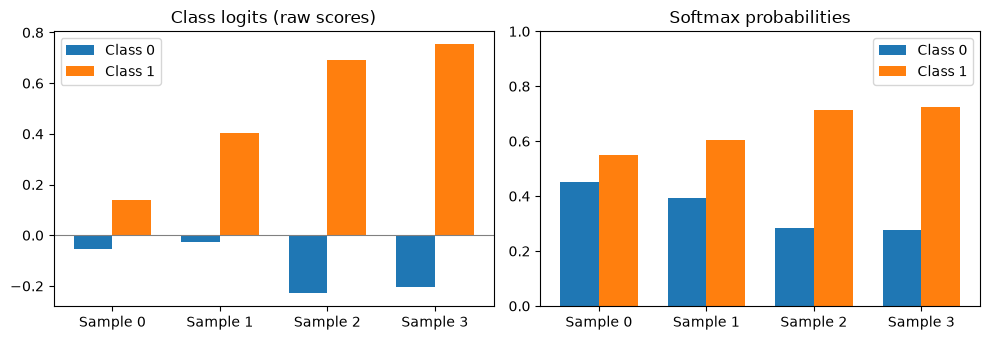

In [4]:
with torch.no_grad():
    checked_logits = head(last_hidden)
assert torch.allclose(checked_logits, logits)
assert logits.shape == (B, 2)
assert sum(p.numel() for p in head.parameters()) == 18
probabilities = logits.softmax(dim=-1)
predictions = logits.argmax(dim=-1)
assert torch.allclose(probabilities.sum(dim=-1), torch.ones(B))
logit_table = pd.DataFrame({
    "sample": range(B),
    "logit_class_0": logits[:,0].detach().numpy(),
    "logit_class_1": logits[:,1].detach().numpy(),
    "probability_class_0": probabilities[:,0].detach().numpy(),
    "probability_class_1": probabilities[:,1].detach().numpy(),
    "predicted_class": predictions.detach().numpy(),
})
print(logit_table.round(6).to_string(index=False))
logit_table.to_csv(out / "rnn_class_logits.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
positions = np.arange(B)
for ax, values, title in zip(axes, [logits, probabilities], ["Class logits (raw scores)", "Softmax probabilities"]):
    for cls, offset in [(0, -.18), (1, .18)]:
        ax.bar(positions+offset, values[:,cls].detach().numpy(), width=.36, label=f"Class {cls}")
    ax.set_xticks(positions, [f"Sample {i}" for i in range(B)])
    ax.set_title(title)
    ax.legend()
axes[0].axhline(0, color="grey", linewidth=.8)
axes[1].set_ylim(0,1)
fig.tight_layout()
fig.savefig(out / "rnn_logits_probabilities.png", dpi=140)
plt.show()
plt.close(fig)

## 4. 모든 시점의 logits와 배치 크기 변경
이번 원본은 시퀀스 하나당 클래스 하나를 예측하는 형태입니다. `head(output)`을 계산하면 같은 Linear 층이 각 시점에 적용되어 `(B,6,2)`가 됩니다. 이 결과를 시점별 분류로 학습하려면 각 시점의 정답 `(B,6)`이 필요합니다. 시퀀스 전체의 정답 `(B,)`과 구분해야 합니다.

B는 처리할 자료 수이므로 1이나 2로 바뀌어도 RNN의 input_size와 hidden_size, Linear의 입출력 크기를 바꿀 필요는 없습니다.

In [5]:
with torch.no_grad():
    per_time_logits = head(output)
assert per_time_logits.shape == (B, 6, 2)
assert torch.allclose(per_time_logits[:,-1,:], logits)
print("모든 시점 logits:", tuple(per_time_logits.shape))
print("마지막 시점 logits 일치:", torch.allclose(per_time_logits[:,-1,:], logits))
shape_rows = []
for batch_size in [1, 2, 4]:
    batch_x = x[:batch_size]
    with torch.no_grad():
        batch_output, batch_hidden = rnn(batch_x)
        batch_logits = head(batch_hidden[-1])
    assert batch_logits.shape == (batch_size, 2)
    shape_rows.append({"B": batch_size, "input": str(tuple(batch_x.shape)),
                       "output": str(tuple(batch_output.shape)),
                       "h_n": str(tuple(batch_hidden.shape)),
                       "logits": str(tuple(batch_logits.shape))})
shape_table = pd.DataFrame(shape_rows)
print(shape_table.to_string(index=False))
shape_table.to_csv(out / "rnn_shape_flow.csv", index=False)

모든 시점 logits: (4, 6, 2)
마지막 시점 logits 일치: True
 B     input    output       h_n logits
 1 (1, 6, 3) (1, 6, 8) (1, 1, 8) (1, 2)
 2 (2, 6, 3) (2, 6, 8) (1, 2, 8) (2, 2)
 4 (4, 6, 3) (4, 6, 8) (1, 4, 8) (4, 2)


## 5. 결과 해석 및 추가 실험
기본 B=4일 때 입력 `(4,6,3)`은 RNN을 거쳐 output `(4,6,8)`과 h_n `(1,4,8)`을 만듭니다. 마지막 층의 최종 상태 `(4,8)`에 Linear(8,2)를 적용하면 logits `(4,2)`가 됩니다. 고정 길이·단방향 조건에서 마지막 시점 output과 마지막 층의 h_n이 일치함을 검증했습니다.

### 직접 확인해 볼 내용
- hidden_size를 16으로 바꾸면 output·h_n의 마지막 축과 Linear의 in_features를 모두 16으로 맞춥니다.
- batch_first=False라면 입력을 `(6,B,3)`으로 바꾸고 output도 `(6,B,8)`임을 확인합니다. h_n은 여전히 `(1,B,8)`입니다.
- num_layers=2이면 output은 마지막 층의 전체 시점 출력이고 h_n 첫 축은 2가 됩니다. h_n[-1]은 마지막 층의 최종 상태입니다.

### 자주 하는 실수 점검
- 입력 특성 수 3과 은닉 특성 수 8을 혼동하지 않았는가?
- batch_first가 h_n에도 적용된다고 생각하지 않았는가?
- head를 생성한 뒤 실제 입력 `h_n[-1]`을 전달했는가?
- logits를 확률이나 정확도로 해석하지 않았는가?
- 이 예제에는 학습과 실제 정답이 없다는 점을 구분했는가?